<a href="https://colab.research.google.com/github/yuvrajdsingh27-cell/sales_app/blob/main/Copy_of_BA(17_10_2026).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
pd.read_csv("/content/delivery_delay.csv")

,Delivery_Distance,Traffic_Congestion,Weather_Condition,Delivery_Slot,Driver_Experience,Num_Stops,Vehicle_Age,Road_Condition_Score,Package_Weight,Fuel_Efficiency,Warehouse_Processing_Time,Delivery_Delay
0,19.352466,4,3,2,16,6,9,3,33.623131,13.018318,58,1
1,47.585001,3,2,1,10,4,2,3,20.810034,15.126948,26,0
2,36.867703,5,3,2,18,3,9,3,23.799699,11.261724,72,1
3,30.334266,1,2,3,6,7,8,2,2.932845,15.960185,64,1
4,8.644913,5,1,1,19,2,9,2,9.957576,12.827934,32,1
...,...,...,...,...,...,...,...,...,...,...,...,...
995,5.487522,2,3,2,4,8,2,3,35.422084,5.923146,82,0
996,45.948365,4,1,1,2,1,2,1,33.753074,9.049605,79,0
997,7.704113,5,1,3,16,1,9,2,20.019887,16.526316,27,1
998,47.561630,4,3,2,18,8,1,4,0.563579,18.275230,87,1


In [ ]:
df = pd.read_csv("/content/delivery_delay.csv")
X = df.drop("Delivery_Delay", axis=1)
y = df["Delivery_Delay"]

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2, random_state=42)

In [ ]:
X_train.shape

(800, 11)

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
logistic=LogisticRegression()

In [ ]:
logistic.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
X.columns

Index(['Delivery_Distance', 'Traffic_Congestion', 'Weather_Condition',
       'Delivery_Slot', 'Driver_Experience', 'Num_Stops', 'Vehicle_Age',
       'Road_Condition_Score', 'Package_Weight', 'Fuel_Efficiency',
       'Warehouse_Processing_Time'],
      dtype='object')

In [ ]:
logistic.predict([[120,5,4,2,3,2,5,3,30.5,10.95,120]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

In [ ]:
logistic.predict([[120,5,4,2,3,2,5,3,30.5,10.95,120]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

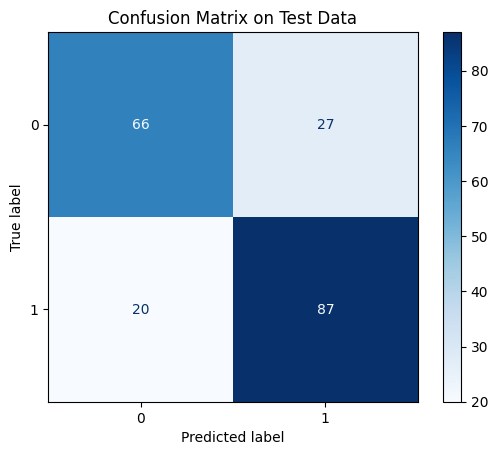

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate predictions on the test set
y_pred = logistic.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logistic.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix on Test Data')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy on Test Data: {accuracy:.4f} ({accuracy * 100:.2f}%)")

Accuracy on Test Data: 0.7650 (76.50%)


In [ ]:
from sklearn.metrics import recall_score

# Calculate recall
recall = recall_score(y_test, y_pred)
print(f"Recall on Test Data: {recall:.4f} ({recall * 100:.2f}%)")

Recall on Test Data: 0.8131 (81.31%)


In [ ]:
from sklearn.metrics import f1_score

# Calculate F1 score
f1 = f1_score(y_test, y_pred)
print(f"F1 Score on Test Data: {f1:.4f} ({f1 * 100:.2f}%)")

F1 Score on Test Data: 0.7873 (78.73%)


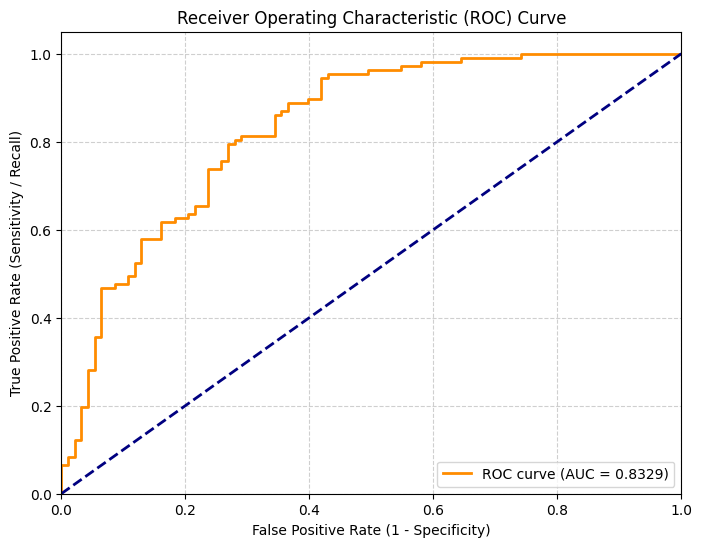

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class (class 1)
y_probs = logistic.predict_proba(X_test)[:, 1]

# Calculate the ROC Curve details
fpr, tpr, thresholds = roc_curve(y_test, y_probs)

# Calculate Area Under the Curve (AUC)
auc_score = roc_auc_score(y_test, y_probs)

# Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
import numpy as np

# Calculate Specificity (1 - FPR)
specificity = 1 - fpr

# Calculate the G-Mean for each threshold
gmeans = np.sqrt(tpr * specificity)

# Locate the index of the largest G-Mean
ix = np.argmax(gmeans)
best_threshold = thresholds[ix]
best_gmean = gmeans[ix]

print(f"Best Threshold: {best_threshold:.4f}")
print(f"G-Mean at this threshold: {best_gmean:.4f}")
print(f"Corresponding True Positive Rate (Sensitivity): {tpr[ix]:.4f}")
print(f"Corresponding False Positive Rate: {fpr[ix]:.4f}")

Best Threshold: 0.5459
G-Mean at this threshold: 0.7621
Corresponding True Positive Rate (Sensitivity): 0.7944
Corresponding False Positive Rate: 0.2688


--- Metrics with Custom Threshold: 0.54 ---
Accuracy: 0.7650 (76.50%)
Recall:   0.8037 (80.37%)
F1 Score: 0.7854 (78.54%)


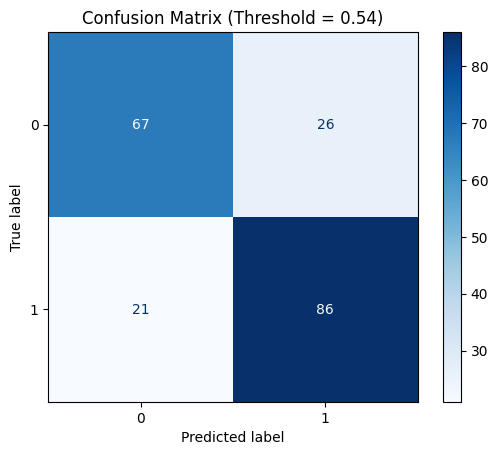

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define the custom threshold
threshold = 0.54

# Apply the 0.54 threshold to predictions
y_pred_custom = (y_probs >= threshold).astype(int)

# Calculate metrics with the custom threshold
acc_custom = accuracy_score(y_test, y_pred_custom)
rec_custom = recall_score(y_test, y_pred_custom)
f1_custom = f1_score(y_test, y_pred_custom)

print(f"--- Metrics with Custom Threshold: {threshold} ---")
print(f"Accuracy: {acc_custom:.4f} ({acc_custom * 100:.2f}%)")
print(f"Recall:   {rec_custom:.4f} ({rec_custom * 100:.2f}%)")
print(f"F1 Score: {f1_custom:.4f} ({f1_custom * 100:.2f}%)")

# Compute and plot the new confusion matrix
cm_custom = confusion_matrix(y_test, y_pred_custom)
disp_custom = ConfusionMatrixDisplay(confusion_matrix=cm_custom, display_labels=logistic.classes_)
disp_custom.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix (Threshold = {threshold})')
plt.show()

In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin

class ThresholdedLogisticRegression(BaseEstimator, ClassifierMixin):
    def __init__(self, base_model, threshold=0.54):
        self.base_model = base_model
        self.threshold = threshold
        self.classes_ = base_model.classes_

    def fit(self, X, y):
        # The base model is already fitted, but we keep this for scikit-learn compatibility
        self.base_model.fit(X, y)
        return self

    def predict(self, X):
        # Predict probabilities for the positive class
        probs = self.base_model.predict_proba(X)[:, 1]
        # Apply the threshold
        return (probs >= self.threshold).astype(int)

    def predict_proba(self, X):
        return self.base_model.predict_proba(X)

# Instantiate and wrap our trained model
custom_threshold_model = ThresholdedLogisticRegression(base_model=logistic, threshold=0.54)

# Now we can use standard .predict()
predictions = custom_threshold_model.predict(X_test)
print("First 10 predictions using the custom 0.54 model wrapper:")
print(predictions[:10])

First 10 predictions using the custom 0.54 model wrapper:
[1 1 0 1 1 1 0 1 0 1]


In [ ]:
from sklearn.metrics import accuracy_score

# Predict using the custom threshold model
custom_preds = custom_threshold_model.predict(X_test)

# Calculate accuracy
custom_accuracy = accuracy_score(y_test, custom_preds)
print(f"Accuracy with 0.54 threshold model: {custom_accuracy:.4f} ({custom_accuracy * 100:.2f}%)")

Accuracy with 0.54 threshold model: 0.7650 (76.50%)


### Support Vector Classifier (SVC) Optimization
We will perform a Grid Search over `kernel`, `C`, and `gamma` parameters to find the optimal combination for our dataset.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Safely load the dataset and recreate splits in case variables were lost from the kernel
df = pd.read_csv('/content/delivery_delay.csv')
X = df.drop('Delivery_Delay', axis=1)
y = df['Delivery_Delay']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardizing features is important for SVM performance
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(probability=True, random_state=42))
])

# Define parameter grid
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'svc__kernel': ['linear', 'rbf', 'poly']
}

# Initialize GridSearchCV
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

Best Parameters: {'svc__C': 100, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.8875


Test Accuracy: 0.8900 (89.00%)

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.90      0.88        93
           1       0.91      0.88      0.90       107

    accuracy                           0.89       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.89      0.89      0.89       200



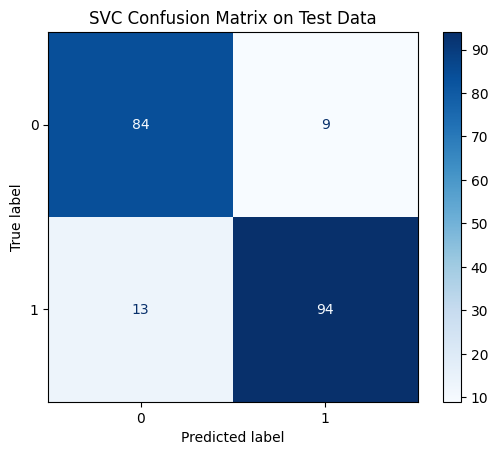

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Evaluate the best model on the test data
best_model = grid_search.best_estimator_
y_pred_svc = best_model.predict(X_test)

# Display performance metrics
test_acc = accuracy_score(y_test, y_pred_svc)
print(f"Test Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_svc))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_svc)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('SVC Confusion Matrix on Test Data')
plt.show()

In [ ]:
import joblib

# Save the best estimator model from the grid search
joblib_file = "best_svc_model.joblib"
joblib.dump(best_model, joblib_file)
print(f"Model successfully saved to {joblib_file}")

Model successfully saved to best_svc_model.joblib


### K-Nearest Neighbors (KNN) Classification
Next, we will train a KNN model, optimize the number of neighbors using Grid Search, and evaluate its performance.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# KNN is highly sensitive to distance metrics, so feature scaling is required
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Define the search space for n_neighbors
knn_param_grid = {
    'knn__n_neighbors': list(range(1, 31))
}

# Run Grid Search
knn_grid_search = GridSearchCV(knn_pipeline, knn_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
knn_grid_search.fit(X_train, y_train)

print("Best Parameters:", knn_grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {knn_grid_search.best_score_:.4f}")

Best Parameters: {'knn__n_neighbors': 19}
Best Cross-Validation Accuracy: 0.8425


KNN Test Accuracy: 0.8300 (83.00%)

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.86      0.82        93
           1       0.87      0.80      0.83       107

    accuracy                           0.83       200
   macro avg       0.83      0.83      0.83       200
weighted avg       0.83      0.83      0.83       200



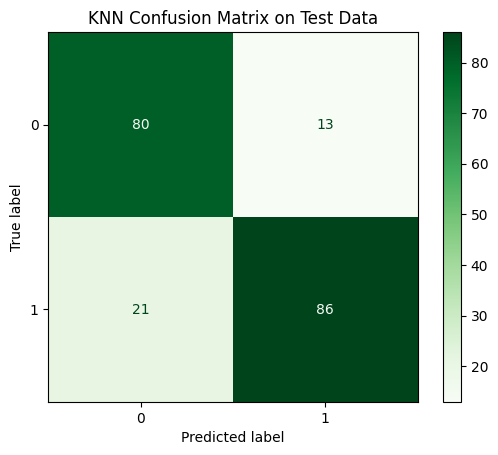

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Evaluate the best KNN model on the test data
best_knn_model = knn_grid_search.best_estimator_
y_pred_knn = best_knn_model.predict(X_test)

# Display accuracy
knn_test_acc = accuracy_score(y_test, y_pred_knn)
print(f"KNN Test Accuracy: {knn_test_acc:.4f} ({knn_test_acc * 100:.2f}%)\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_knn))

# Plot Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=best_knn_model.classes_)
disp_knn.plot(cmap=plt.cm.Greens)
plt.title('KNN Confusion Matrix on Test Data')
plt.show()

### Decision Tree Classification
Now, we will train a Decision Tree model, optimize its depth and splitting criteria using Grid Search, and evaluate its accuracy on the test dataset.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Initialize Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)

# Define parameter grid
dt_param_grid = {
    'max_depth': [None, 3, 5, 7, 10, 15],
    'min_samples_split': [2, 5, 10, 20],
    'criterion': ['gini', 'entropy']
}

# Set up Grid Search
dt_grid_search = GridSearchCV(dt_model, dt_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid_search.fit(X_train, y_train)

print("Best Parameters:", dt_grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {dt_grid_search.best_score_:.4f}")

Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 2}
Best Cross-Validation Accuracy: 1.0000


Decision Tree Test Accuracy: 1.0000 (100.00%)

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        93
           1       1.00      1.00      1.00       107

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



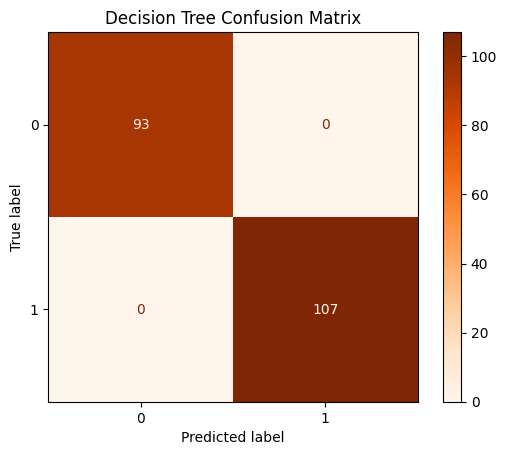

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get the best estimator
best_dt_model = dt_grid_search.best_estimator_
y_pred_dt = best_dt_model.predict(X_test)

# Calculate and display the metrics
dt_test_acc = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Test Accuracy: {dt_test_acc:.4f} ({dt_test_acc * 100:.2f}%)\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

# Plot the Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=best_dt_model.classes_)
disp_dt.plot(cmap=plt.cm.Oranges)
plt.title('Decision Tree Confusion Matrix')
plt.show()

### Visualizing the Decision Tree
We will visualize the decision logic of our optimized Decision Tree model. To ensure the tree diagram remains readable, we will limit the plotted depth to 3 (`max_depth=3`).

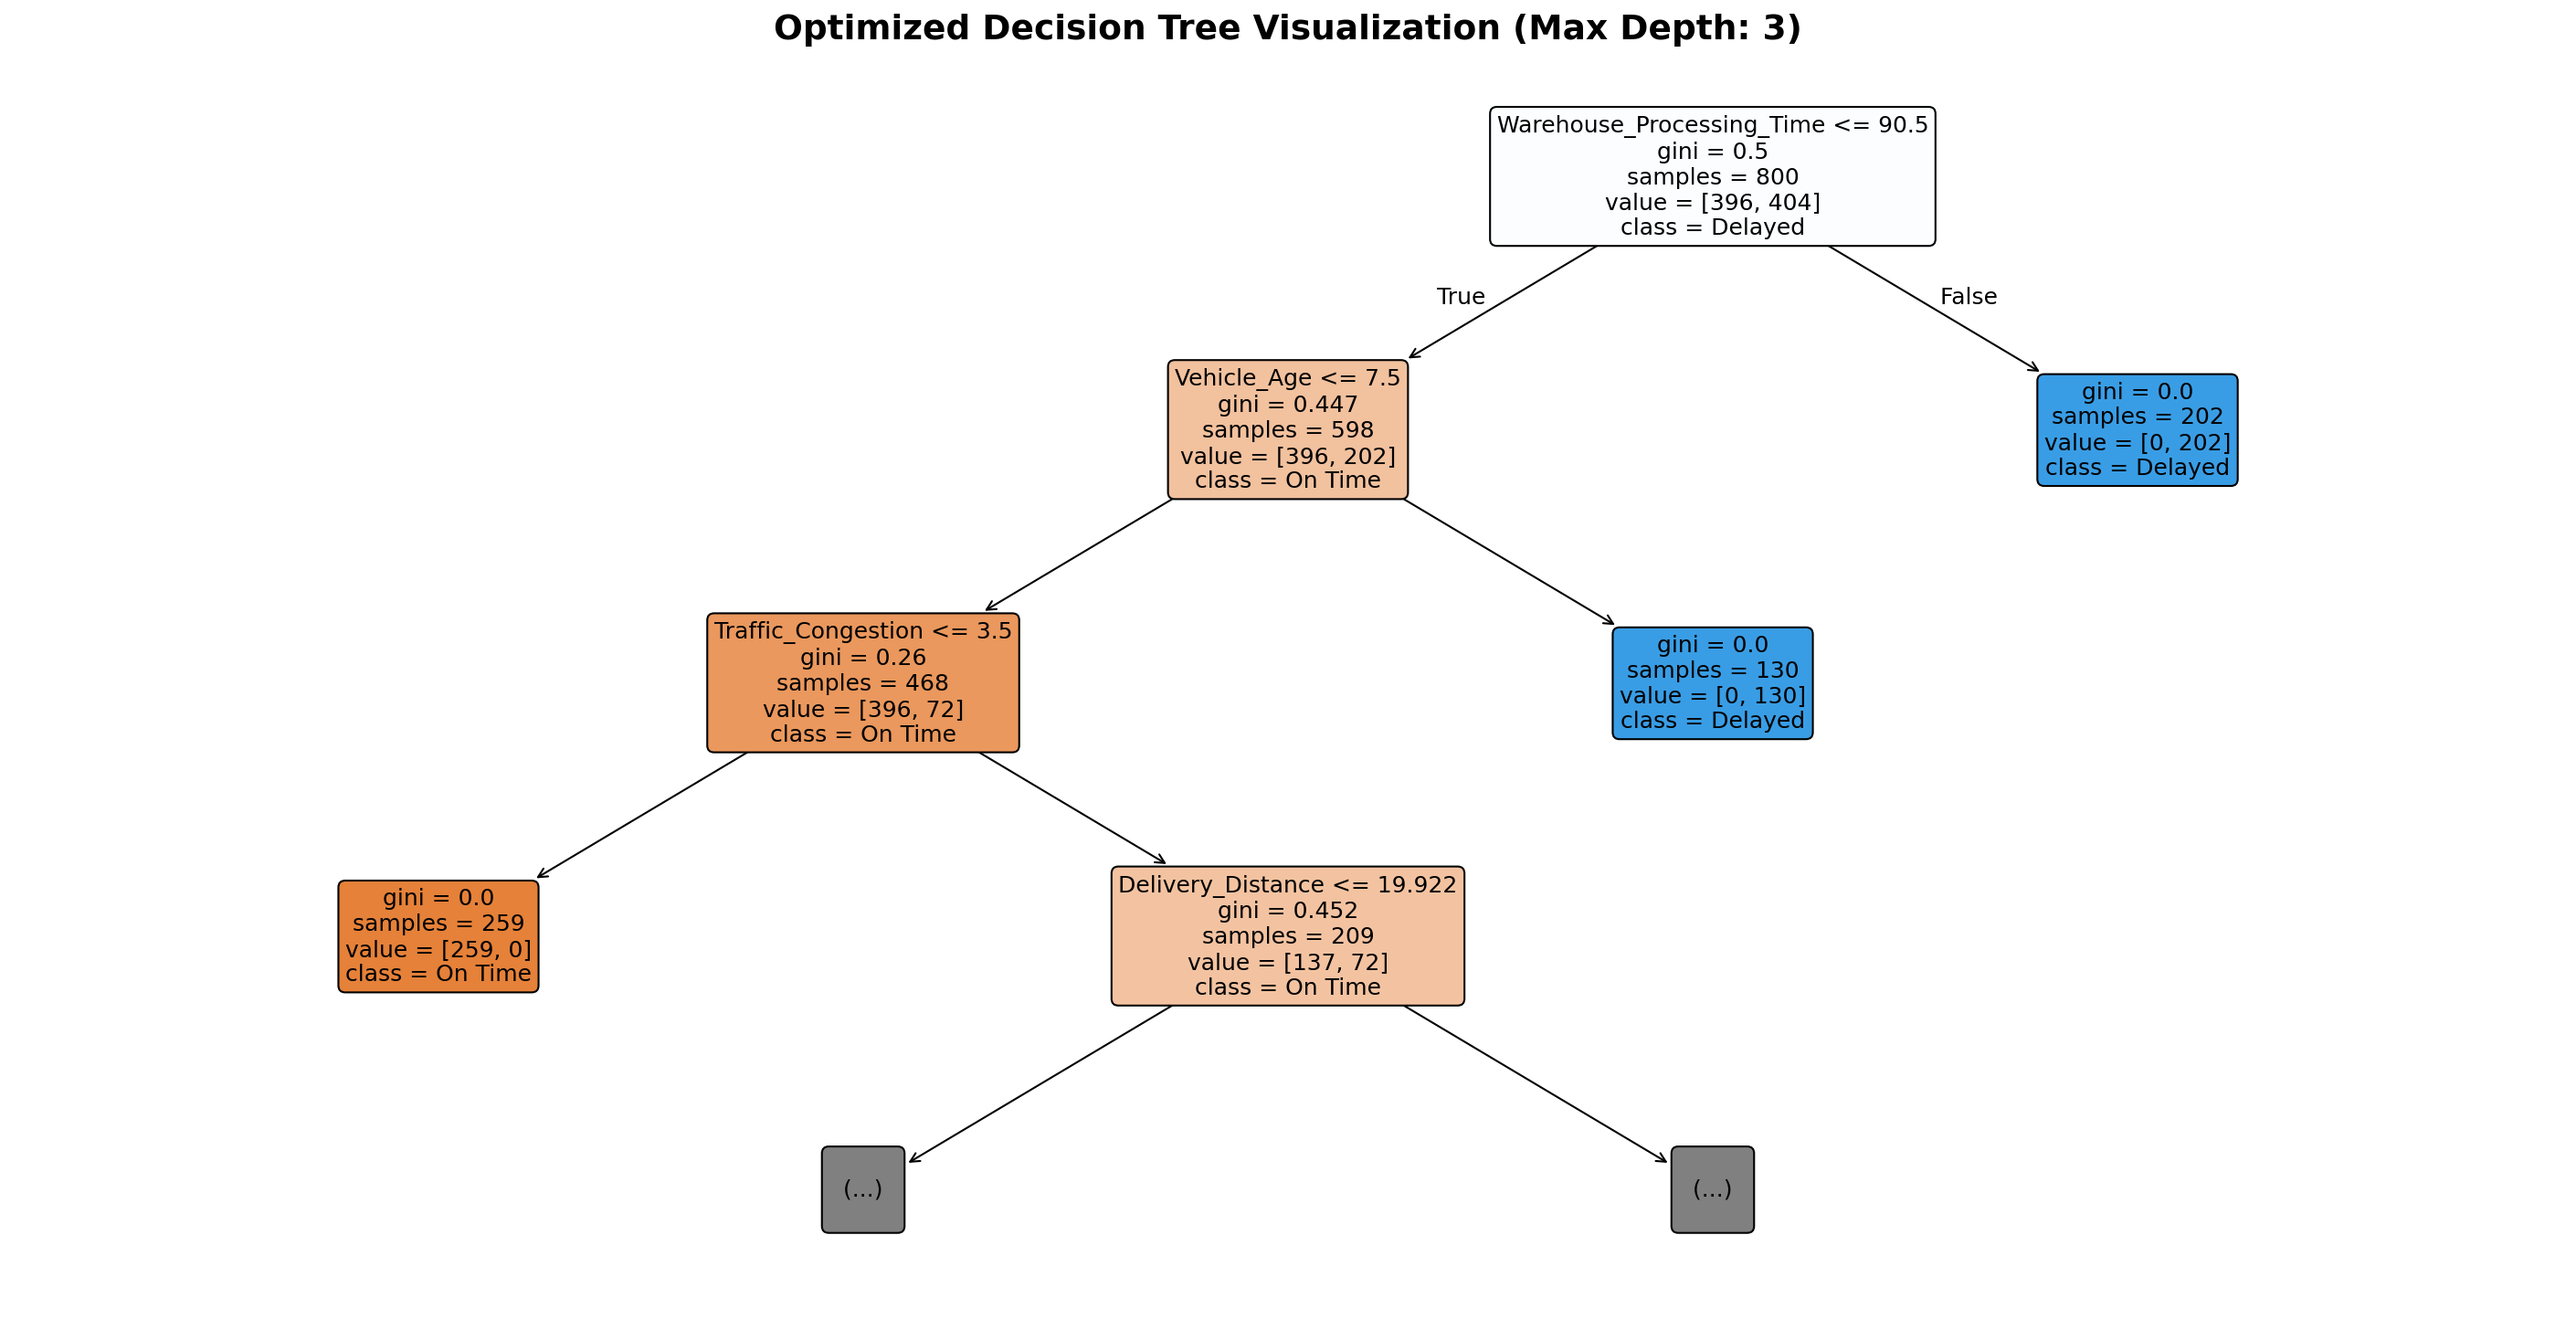

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Configure figure size for better visual quality
plt.figure(figsize=(24, 12), dpi=150)

# Plot the decision tree with limited depth for readability
plot_tree(
    best_dt_model,
    max_depth=3,
    feature_names=X.columns.tolist(),
    class_names=['On Time', 'Delayed'],
    filled=True,
    rounded=True,
    fontsize=12
)

plt.title('Optimized Decision Tree Visualization (Max Depth: 3)', fontsize=18, fontweight='bold')
plt.show()